# Shadow feedback in a fully connected network: 2-task multi-MNIST

Fully connected, our method falls short of the ideal connectivity on 2-task multi-MNIST (`05_multi_mnist.ipynb`,
Question 1): it splits the hidden units unevenly between the tasks early on and never revises the split, while its
units do not mix the tasks. Here each hidden unit is paired with one output (the network has one unit per output;
unit $j$ with output $j$), and that connection gets a fixed shadow weight of $+1$ or $-1$, drawn at random at the
start and used only in the backward pass. The forward pass is unchanged and the output weights keep their true
gradients. Two versions:
- *shadow feedback*: unit $j$'s gradient comes only from output $j$, through the shadow weight. Each task then has as
  many units learning its features as it has outputs, so the split is even by construction, without knowing the tasks.
- *shadow feedback + backprop*: unit $j$'s gradient comes from every output through the output weights, as in backprop,
  except that the weight from output $j$ counts as the shadow weight unless the real one is larger in magnitude.

Shadow feedback builds in what the right split is (one unit per output), so it is kept apart from the main line of
experiments, which looks for a learner that finds the split itself.

**Problem, network and learner.** As in `05_multi_mnist.ipynb`: 2 concatenated 14×14 MNIST images, one task's labels
remapped every 1000 steps, summed softmax cross-entropy; 392 inputs → 20 LTU hidden units → 20 outputs; our learner
(centered hidden units with a matching centered backward pass, input weights starting at $U(-\alpha_0, \alpha_0)$),
with $\alpha_0 = 10^{-8}$, meta step-size 0.01 and $\tau = 10^4$. Both versions train the fully connected network, and
are compared with backprop in the same network and in the ideal one (10 hidden units per task, each reading only its
own task's image and feeding only its own task's logits). 1M steps and 30 seeds; seed $s$ gives every run the same
initial-weight draw, images and label changes.

**Hypotheses**, on the online accuracy (over every task) averaged over the last 10% of training, pooled over seeds:
- **H1**: fully connected with shadow feedback is at most 1 percentage point below ideal connectivity.
- **H2**: fully connected with shadow feedback + backprop is at most 1 percentage point below ideal connectivity.

**Diagnostics**, fixed in advance: path purity and allocation, as in `05_multi_mnist.ipynb`.

In [1]:
from typing import NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from torchvision import datasets

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd

sns.set_theme('notebook', 'white')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_TASKS = 2
N_PIXELS = 14 * 14                   # MNIST downsampled from 28x28 by averaging 2x2 blocks
N_CLASSES = 10
PERMUTE_PERIOD = 2000 // N_TASKS     # steps between label changes, each of one task chosen at random

# --- Network ---
N_HIDDEN_PER_TASK = N_CLASSES        # one hidden unit per output (shadow feedback pairs unit j with output j)

# --- Autostep ---
INIT_STEP_SIZE = 1e-8
META_STEP_SIZE = 0.01
TAU = 1e4
EMA_RATE = 1e-3                      # rate of the hidden units' running means (used by ours)

# --- Training ---
NUM_STEPS = 1_000_000
N_SEEDS = 30
N_WINDOWS = 250                      # each window records its mean loss, accuracy and path purity

# --- Hypotheses ---
FINAL_FRACTION = 0.1                 # accuracy is compared over the last 10% of training ...
ACCURACY_TOLERANCE = 0.01            # ... with this tolerance (1 percentage point)

In [3]:
mnist = datasets.MNIST(root='/tmp/data', train=True, download=True)
images = np.asarray(mnist.data, dtype=np.float32).reshape(-1, 14, 2, 14, 2).mean((2, 4)).reshape(-1, N_PIXELS) / 255.0
IMAGES = jnp.asarray((images - images.mean(0)) / images.std())     # per-pixel centered, one global scale
DIGITS = jnp.asarray(np.asarray(mnist.targets))


class Stream(NamedTuple):
    key: jax.Array
    step: jax.Array
    label_maps: jax.Array     # (task, digit): each task's current label for each digit


def init_stream(key):
    return Stream(key, jnp.array(0), jnp.tile(jnp.arange(N_CLASSES), (N_TASKS, 1)))


def next_sample(stream):
    # One sample: an independent training image per task, concatenated, and each task's label. Every PERMUTE_PERIOD
    # steps, one task chosen at random first gets a new random label mapping.
    key, task_key, map_key, image_key = jax.random.split(stream.key, 4)
    step = stream.step + 1
    changes = (step % PERMUTE_PERIOD == 0) & (jnp.arange(N_TASKS) == jax.random.randint(task_key, (), 0, N_TASKS))
    label_maps = jnp.where(changes[:, None], jax.random.permutation(map_key, N_CLASSES)[None], stream.label_maps)
    index = jax.random.randint(image_key, (N_TASKS,), 0, IMAGES.shape[0])
    labels = label_maps[jnp.arange(N_TASKS), DIGITS[index]]
    return Stream(key, step, label_maps), (IMAGES[index].reshape(-1), labels)

In [4]:
LAYERS = ('w1', 'w2')

input_task = np.repeat(np.arange(N_TASKS), N_PIXELS)
hidden_task = np.repeat(np.arange(N_TASKS), N_HIDDEN_PER_TASK)
output_task = np.repeat(np.arange(N_TASKS), N_CLASSES)


def with_bias_column(mask, bias):
    # The last column of each weight matrix reads the constant-1 input.
    return np.concatenate([mask, np.full((mask.shape[0], 1), bias)], axis=1)


# Masks are shaped like the weight matrices: w1 is (hidden, inputs + 1), w2 is (outputs, hidden + 1).
same_task = {'w1': hidden_task[:, None] == input_task[None, :],
             'w2': output_task[:, None] == hidden_task[None, :]}
MASKS = {'ideal connectivity': {k: with_bias_column(m, True) for k, m in same_task.items()},
         'fully connected': {k: np.ones((m.shape[0], m.shape[1] + 1), bool) for k, m in same_task.items()}}

for name, masks in MASKS.items():
    print(f'{name}: ' + ', '.join(f'{k} {masks[k][:, :-1].sum():,} weights' for k in LAYERS))

ideal connectivity: w1 3,920 weights, w2 200 weights
fully connected: w1 7,840 weights, w2 400 weights


## Learner

In [5]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


class Learner(NamedTuple):
    w: dict                   # {'w1': ..., 'w2': ...}; masked-out weights stay at exactly 0 (their gradient is 0)
    opt: IDBDState
    hidden_mean: jax.Array    # each hidden unit's running mean firing rate
    hidden_slope: jax.Array   # running mean of sigma'(z) x, each hidden unit's derivative w.r.t. each input weight
    shadow_weights: jax.Array # each hidden unit's fixed +-1 weight from its paired output (shadow feedback only)


def init_learner(key, masks, ours):
    # Input weights: U(-INIT_STEP_SIZE, INIT_STEP_SIZE) for ours, LeCun uniform over each unit's inputs otherwise. Both
    # scale the same draw.
    fan_in = masks['w1'][:, :-1].sum(1, keepdims=True)
    bound = INIT_STEP_SIZE if ours else np.sqrt(3.0 / fan_in)
    w1 = jax.random.uniform(key, masks['w1'].shape, minval=-1.0, maxval=1.0) * bound * masks['w1']
    w = {'w1': w1.at[:, -1].set(0.0), 'w2': jnp.zeros(masks['w2'].shape)}
    # A zero-threshold LTU with symmetric inputs fires with probability 1/2, so the means start out exact. The slope
    # starts at sigma'(0) E[x]: 0 for the zero-mean inputs, 1/4 for the bias.
    n_hidden = masks['w1'].shape[0]
    return Learner(w, OPTIMIZER.init(w), jnp.full(n_hidden, 0.5), jnp.zeros(masks['w1'].shape).at[:, -1].set(0.25),
                   jax.random.rademacher(jax.random.fold_in(key, 1), (n_hidden,), dtype=jnp.float32))


def forward(w, x, learner, masks, ours, backward='backprop'):
    # Returns the prediction, each weight's source values (what Autostep normalizes by), and the new running means.
    x = jnp.append(x, 1.0)
    w1 = w['w1'] * masks['w1']
    z = w1 @ x
    h = ltu(z)

    # Running means, updated with this sample before they are used. No gradient flows through them.
    mean = learner.hidden_mean + EMA_RATE * (jax.lax.stop_gradient(h) - learner.hidden_mean)
    sigma_prime = jax.lax.stop_gradient(jax.nn.sigmoid(z) * (1.0 - jax.nn.sigmoid(z)))     # the LTU's surrogate slope
    slope = learner.hidden_slope + EMA_RATE * (sigma_prime[:, None] * x[None, :] - learner.hidden_slope)
    if ours:
        # Send h - m, with the gradient of h - E[h]: each input weight's derivative becomes sigma'(z) x - slope. The
        # correction leaves the value unchanged.
        correction = jnp.sum(slope * w1, axis=1)
        h = h - mean - correction + jax.lax.stop_gradient(correction)

    w2 = w['w2'] * masks['w2']
    if backward == 'backprop':
        y_hat = w2 @ jnp.append(h, 1.0)
    else:
        # Shadow feedback: the outputs read h as usual, but h's gradient comes through a fixed matrix
        # instead of the output weights. With 'shadow', unit j hears only from output j, through its +-1 shadow weight.
        # With 'shadow + backprop', it hears from every output through the output weights, but the weight from output j
        # counts as the shadow weight unless the real one is larger in magnitude. The last two terms cancel in value,
        # and the output weights keep their true gradient.
        n = learner.shadow_weights.shape[0]
        others, paired = jnp.zeros((n, n)), learner.shadow_weights
        if backward == 'shadow + backprop':
            others = w2[:, :-1]
            paired = jnp.where(jnp.abs(jnp.diag(others)) > 1.0, jnp.diag(others), paired)
        feedback = jax.lax.stop_gradient(others.at[jnp.arange(n), jnp.arange(n)].set(paired))    # (output, unit)
        y_hat = w2 @ jnp.append(jax.lax.stop_gradient(h), 1.0) + feedback @ h - jax.lax.stop_gradient(feedback @ h)
    return y_hat, ({'w1': x[None], 'w2': jnp.append(h, 1.0)[None]}, mean, slope)


def learner_step(learner, x, labels, masks, ours, backward='backprop'):
    # One online Autostep update on the summed softmax cross-entropy of every task. Returns the new learner, the loss
    # and the fraction of tasks classified correctly.
    def loss_fn(w):
        logits, aux = forward(w, x, learner, masks, ours, backward)
        logits = logits.reshape(N_TASKS, N_CLASSES)
        return -jnp.sum(jax.nn.log_softmax(logits)[jnp.arange(N_TASKS), labels]), (aux, logits)

    (loss, ((source_values, mean, slope), logits)), grads = jax.value_and_grad(loss_fn, has_aux=True)(learner.w)
    updates, opt = OPTIMIZER.update((grads, None, source_values), learner.opt, learner.w)
    w = {k: learner.w[k] + updates[k] for k in LAYERS}
    return Learner(w, opt, mean, slope, learner.shadow_weights), loss, jnp.mean(logits.argmax(-1) == labels)

## Training

In [6]:
def path_purity(w):
    # The share of all input -> hidden -> output path weight (the product of |w| along the path) that starts and ends
    # in the same task. Biases are left out.
    n_hidden = w['w1'].shape[0]
    reads = jnp.abs(w['w1'][:, :-1]).reshape(n_hidden, N_TASKS, N_PIXELS).sum(-1)      # (unit, task)
    feeds = jnp.abs(w['w2'][:, :-1]).reshape(N_TASKS, N_CLASSES, n_hidden).sum(1).T    # (unit, task)
    return jnp.sum(reads * feeds) / jnp.maximum(jnp.sum(reads.sum(-1) * feeds.sum(-1)), 1e-30)


def allocation(w):
    # How evenly the hidden units are split between the tasks, counting each unit for the task whose outputs it feeds
    # most: 1 when every task has the same number, 0 when all units feed one task.
    n_hidden = w['w1'].shape[0]
    feeds = jnp.abs(w['w2'][:, :-1]).reshape(N_TASKS, N_CLASSES, n_hidden).sum(1)      # (task, unit)
    largest = jnp.max(jnp.bincount(feeds.argmax(0), length=N_TASKS)) / n_hidden
    return (1 - largest) / (1 - 1 / N_TASKS)


def train(key, stream, masks, ours, backward='backprop'):
    # Step 1 on its own, then NUM_STEPS online steps in windows, with the `backward` pass of forward(). Returns the
    # mean loss and accuracy of every window, and the path purity and allocation at its end.
    def one_step(carry, _):
        learner, stream = carry
        stream, (x, labels) = next_sample(stream)
        learner, loss, accuracy = learner_step(learner, x, labels, masks, ours, backward)
        return (learner, stream), (loss, accuracy)

    def window(carry, _):
        carry, (loss, accuracy) = jax.lax.scan(one_step, carry, length=NUM_STEPS // N_WINDOWS)
        w = carry[0].w
        return carry, {'loss': loss.mean(), 'accuracy': accuracy.mean(), 'purity': path_purity(w),
                       'allocation': allocation(w)}

    stream, (x, labels) = next_sample(stream)
    learner, _, _ = learner_step(init_learner(key, masks, ours), x, labels, masks, ours, backward)
    return jax.lax.scan(window, (learner, stream), length=N_WINDOWS)[1]


def run(network, ours, backward='backprop'):
    # Trains one learner (ours, or standard Autostep) on `network` (a key of MASKS) on every seed, vmapped into one
    # scan. Seed s uses init key s and stream s for every run, so runs are paired. Returns per-seed records: loss,
    # accuracy, purity and allocation (seed, window).
    keys = jax.random.split(jax.random.PRNGKey(0), N_SEEDS)
    streams = jax.vmap(init_stream)(jax.random.split(jax.random.PRNGKey(1), N_SEEDS))
    masks = MASKS[network]
    train_seeds = jax.vmap(lambda key, stream: train(key, stream, masks, ours, backward))
    records = jax.jit(train_seeds)(keys, streams)
    return jax.tree.map(np.asarray, records)

## Results

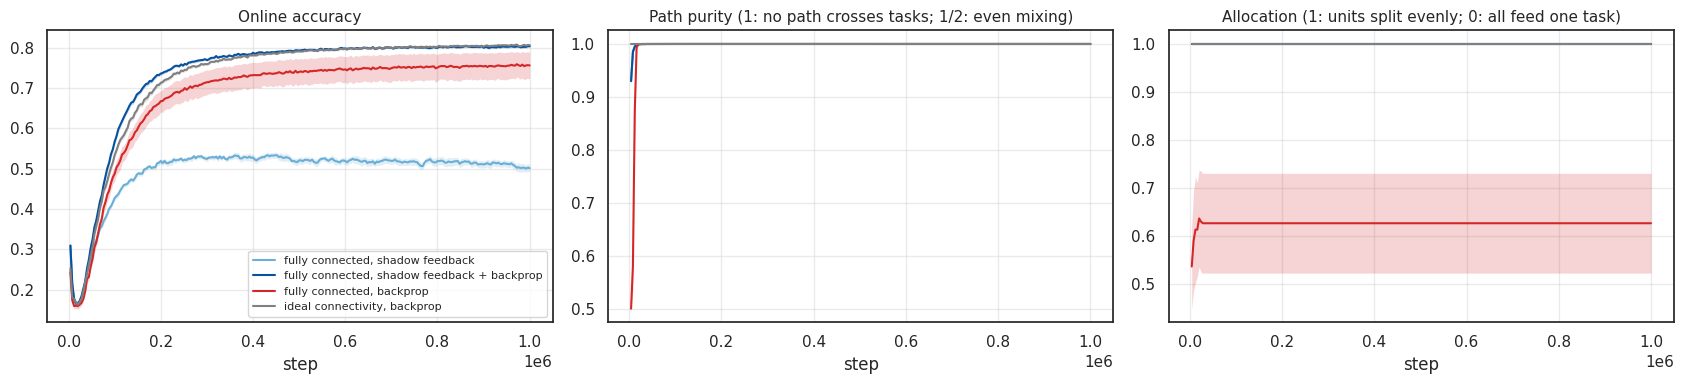

fully connected, shadow feedback              online accuracy 50.91%
fully connected, shadow feedback + backprop   online accuracy 80.24%
fully connected, backprop                     online accuracy 75.56%
ideal connectivity, backprop                  online accuracy 80.59%
H1, fully connected, shadow feedback vs ideal connectivity, backprop: -29.7 points (± 0.7): failed
H2, fully connected, shadow feedback + backprop vs ideal connectivity, backprop: -0.4 points (± 0.2): held


In [7]:
WINDOW_ENDS = np.arange(1, N_WINDOWS + 1) * (NUM_STEPS // N_WINDOWS)
FINAL = slice(-round(N_WINDOWS * FINAL_FRACTION), None)


def plot_runs(runs, colors):
    # Accuracy, path purity and allocation over training for each run in `runs` (mean +- 2 SE over seeds).
    fig, axes = plt.subplots(1, 3, figsize=(17, 4))
    for ax, (key, title) in zip(axes, [('accuracy', 'Online accuracy'),
                                       ('purity', 'Path purity (1: no path crosses tasks; 1/2: even mixing)'),
                                       ('allocation', 'Allocation (1: units split evenly; 0: all feed one task)')]):
        for label, res in runs.items():
            mean, sem = res[key].mean(0), res[key].std(0) / np.sqrt(N_SEEDS)
            ax.plot(WINDOW_ENDS, mean, color=colors[label], lw=1.5, label=label)
            ax.fill_between(WINDOW_ENDS, mean - 2 * sem, mean + 2 * sem, color=colors[label], alpha=0.2, lw=0)
        ax.yaxis.set_major_locator(plt.MultipleLocator(0.1))
        ax.set_xlabel('step')
        ax.set_title(title, fontsize=11)
        ax.grid(alpha=0.4)
    axes[0].legend(fontsize=8)
    fig.tight_layout()
    plt.show()


def final_accuracy(res):
    return res['accuracy'][:, FINAL].mean(1)                 # each seed's accuracy over the last FINAL_FRACTION


def report(runs, tests):
    # Prints every run's accuracy, then for each test (name, label, reference) whether `label` is at most
    # ACCURACY_TOLERANCE below `reference` on paired seeds.
    for label, res in runs.items():
        print(f'{label:<45} online accuracy {final_accuracy(res).mean():.2%}')
    for name, label, reference in tests:
        g = final_accuracy(runs[label]) - final_accuracy(runs[reference])
        print(f'{name}, {label} vs {reference}: {100 * g.mean():+.1f} points '
              f'(± {100 * 2 * g.std() / np.sqrt(N_SEEDS):.1f}): {"held" if g.mean() >= -ACCURACY_TOLERANCE else "failed"}')


shadow_runs = {'fully connected, shadow feedback': run('fully connected', True, backward='shadow'),
               'fully connected, shadow feedback + backprop':
                   run('fully connected', True, backward='shadow + backprop'),
               'fully connected, backprop': run('fully connected', True),
               'ideal connectivity, backprop': run('ideal connectivity', True)}
plot_runs(shadow_runs, {'fully connected, shadow feedback': '#6baed6', 'fully connected, shadow feedback + backprop':
                        '#08519c', 'fully connected, backprop': 'tab:red', 'ideal connectivity, backprop': 'gray'})
report(shadow_runs, [('H1', 'fully connected, shadow feedback', 'ideal connectivity, backprop'),
                     ('H2', 'fully connected, shadow feedback + backprop', 'ideal connectivity, backprop')])

## Results

- **H1 failed.** Shadow feedback alone reaches 50.9% online accuracy, −29.7 points (± 0.7, 2 SE over paired seeds)
  below ideal connectivity, even though its allocation and path purity are both exactly 1. Each unit is tied to one
  output, that is, to one label slot, so it likely has to relearn its feature every time its task's labels are permuted
  (not tested).
- **H2 held.** Shadow feedback + backprop reaches 80.2%, −0.4 points (± 0.2) from ideal connectivity, and 4.7 points
  above backprop in the same network. Its allocation and path purity are exactly 1 in every seed (both lines are
  hidden under the ideal network's), and early on it learns faster than the ideal network. The shadow weight
  guarantees each unit a gradient from its own output, which keeps the split even; the other outputs' gradients likely
  let the units learn features that serve their whole task, and so survive the label permutations.
- Both versions get the even split from knowing that the network should have one unit per output, so neither shows
  that a learner can find the split itself.